# Boundary data

Boundary files (`&BNDF`) hold a quantity on the surfaces of obstructions, for example the
wall temperature. fdsreader attaches them to the obstructions they belong to.

Run FDS on `fds_data/wall_005.fds` first: a room with a fire on the floor, split into 24
meshes with `&MULT`. The walls, floor and ceiling write the wall temperature.

In [1]:
import matplotlib.pyplot as plt

import fdsreader as fds

sim = fds.Simulation("./fds_data")
sim

Simulation(chid=wall_test,
           meshes=24,
           obstructions=5,
           data_3d=5)

## Find an obstruction

`sim.obstructions` holds all obstructions; `filter_by_boundary_data` keeps those with
boundary data. Look one up by its `ID` or by position with `get_nearest`.

In [2]:
print(sorted(q.name for q in sim.obstructions.quantities))
print([obst.id for obst in sim.obstructions.filter_by_boundary_data()])

wall = sim.obstructions.get_by_id("Wand_r")
print(wall)
print("bounding box:", wall.bounding_box)
print("output times:", wall.n_t(), "from", wall.times[0], "to", wall.times[-1], "s")

['BACK WALL TEMPERATURE', 'WALL TEMPERATURE']
['Boden', 'Decke', 'Wand_v', 'Wand_r', 'Golf_brandfläche']
Obstruction(id=Wand_r, Bounding-Box=Extent([-0.85, -0.80] x [-1.00, 2.40] x [0.00, 3.00]), SubObstructions=5, Quantities=['back', 'temp'])
bounding box: Extent([-0.85, -0.80] x [-1.00, 2.40] x [0.00, 3.00])
output times: 53 from 0.0 to 20.0 s


## Data of one face

An obstruction has up to six faces, numbered by the axis they face: `-1`/`1` for -x/+x,
`-2`/`2` for -y/+y and `-3`/`3` for -z/+z. `get_global_boundary_data_arrays` merges the
parts of the obstruction in all meshes into one array per face, with time as the first
axis. This wall is thin in x, so its large faces are `-1` and `1`.

In [3]:
quantity = "WALL TEMPERATURE"
faces = wall.get_global_boundary_data_arrays(quantity)
face = faces[1]
print("faces:", list(faces), " +x face:", face.shape, "(time, y, z)")

faces: [-1, 1, 2]  +x face: (53, 68, 60) (time, y, z)


The data is cell-centred, so the face spans exactly the bounding box of the wall in y
and z. The case runs for only 20 s, so the wall warms by less than a kelvin; the plume
reaches it in the last seconds:

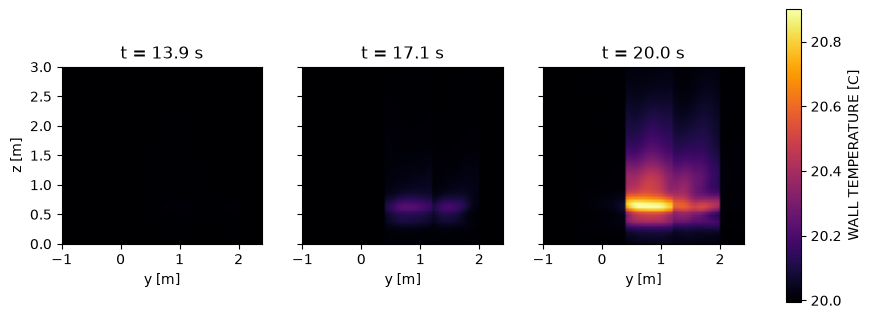

In [4]:
box = wall.bounding_box
extent = (box.y_start, box.y_end, box.z_start, box.z_end)
vmin, vmax = face.min(), face.max()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, time in zip(axes, (14, 17, 20)):
    t = wall.get_nearest_timestep(time)
    image = ax.imshow(face[t].T, origin="lower", extent=extent, vmin=vmin, vmax=vmax, cmap="inferno")
    ax.set(title=f"t = {wall.times[t]:.1f} s", xlabel="y [m]")
axes[0].set_ylabel("z [m]")
fig.colorbar(image, ax=axes, label=f"{quantity} [C]");

## Over time

The hottest point of the face at every output time:

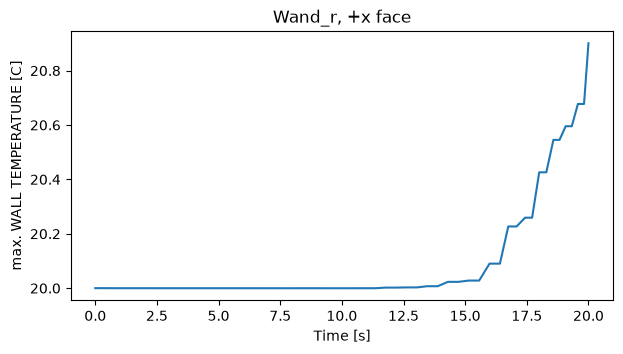

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(wall.times, face.max(axis=(1, 2)))
ax.set(xlabel="Time [s]", ylabel=f"max. {quantity} [C]", title=f"{wall.id}, +x face");

## Walls of the simulation domain

Data on walls of the simulation domain that are not part of an obstruction, for example the
burning rate on the ground of an outdoor case, belong to the meshes. FDS may split such a wall into
several patches, e.g. where a vent begins; `sim.meshes.get_global_boundary_data_arrays` combines
them over all meshes in the same way as for an obstruction:

```python
walls = sim.meshes.get_global_boundary_data_arrays("BURNING RATE")
ground = walls[3]  # faces +z: (time, x, y)
```

In this example the room stands on the obstruction `Boden` and the outer faces are open, so
these data only hold the ambient temperature.

More in the [API reference](https://fdsreader.readthedocs.io/en/latest/api/bndf.html).